# Практичні роботи 4–7

## Мініпроєкт «Порівняння класичних моделей класифікації»

**Дисципліна:** Розпізнавання образів та класичне машинне навчання
**Студент:** Святішенко Дмитро
**Група:** ІН-32/2
**Дата виконання:** 01.11.2026

### Мета роботи

Навчитися будувати відтворюваний конвеєр машинного навчання, застосовувати класичні алгоритми
класифікації, налаштовувати їхні основні гіперпараметри та коректно порівнювати моделі за однаковими
умовами без використання тестової вибірки для підбору рішень.

| Частина | Практична робота | Зміст |
|---|---|---|
| I | 4 | підготовка даних, Pipeline, логістична регресія |
| II | 5 | k-NN, Gaussian Naive Bayes, LDA та QDA |
| III | 6 | лінійна SVM, RBF-SVM і пошук гіперпараметрів |
| IV | 7 | порівняння за CV, вибір фінальної моделі, одноразове тестування, збереження Pipeline |

> **Етичне застереження.** Результати цього навчального мініпроєкту не є медичним діагнозом
> і не повинні використовуватися для клінічних рішень.

## Постановка задачі

- **Об'єкт дослідження** — пацієнти клініки Cleveland (набір Heart Disease, UCI Machine Learning Repository, 303 записи).
- **Ознаки** — 13 характеристик пацієнта: вік, стать, тип болю в грудях, тиск у стані спокою, холестерин,
  рівень цукру натще, результати ЕКГ, максимальний пульс, стенокардія під час навантаження, депресія ST,
  нахил сегмента ST, кількість уражених судин і результат таліевого тесту.
- **Цільова змінна** — `target`: 0 — ознаки серцевого захворювання відсутні, 1 — наявні
  (початкові значення `num` = 1–4 об'єднано в клас 1).
- **Кількість класів** — 2 (бінарна класифікація з навчанням за розміченими даними).
- **Позитивний клас** — **1** (наявність ознак захворювання). Саме для нього обчислюються precision, recall і F1.
- **Практична мета** — за характеристиками пацієнта визначити, чи належить він до класу з наявністю
  ознак серцевого захворювання.
- **Основна метрика (обрана до початку експериментів)** — **F1-міра позитивного класу**. Додаткові:
  ROC AUC (якість ранжування) і recall (частка виявлених хворих — пропуск позитивного класу тут
  найнебезпечніший), допоміжні — precision, accuracy і час навчання.

### Правило вибору фінальної моделі (зафіксовано заздалегідь)

1. Для кожного алгоритму найкращу конфігурацію обираємо за найбільшим середнім **CV F1**
   (за рівності — за більшим CV ROC AUC, далі — простіша модель).
2. Серед найкращих конфігурацій алгоритмів у короткий список потрапляють моделі, чий CV F1 відстає
   від лідера не більше ніж на **0,01**.
3. З короткого списку обирається модель із меншим стандартним відхиленням CV F1 і більшим CV recall;
   за рівності — простіша й краще інтерпретована.
4. Тестова вибірка відкривається лише один раз — для вже зафіксованої фінальної моделі.

# ЧАСТИНА I. Практична робота 4

## Підготовка даних, Pipeline і логістична регресія

### 1. Підключення бібліотек

In [1]:
from pathlib import Path
import sys
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
    GridSearchCV
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.svm import SVC

from IPython.display import display

RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

In [2]:
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)

Python: 3.12.11
pandas: 3.0.6
scikit-learn: 1.9.1
joblib: 1.6.0


### 2. Підключення Google Drive і шляхи проєкту

Мініпроєкт розміщено в папці `classification-mini-project/` репозиторію `pattern-recognition-practice`.
Поза Colab робочою папкою вважається корінь мініпроєкту (Notebook лежить у `notebooks/`).

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Notebook виконується поза Google Colab — використовується локальна папка проєкту.")

Notebook виконується поза Google Colab — використовується локальна папка проєкту.


In [4]:
if IN_COLAB:
    PROJECT_DIR = Path(
        "/content/drive/MyDrive/pattern-recognition-practice/classification-mini-project"
    )
else:
    PROJECT_DIR = Path.cwd().parent

DATA_PATH = PROJECT_DIR / "data" / "heart_disease.csv"
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

MODEL_PATH = MODELS_DIR / "best_classifier.joblib"
CV_COMPARISON_PATH = REPORTS_DIR / "cv_model_comparison.csv"
TEST_METRICS_PATH = REPORTS_DIR / "final_test_metrics.csv"

for folder in (DATA_PATH.parent, MODELS_DIR, REPORTS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Файл даних:", DATA_PATH.relative_to(PROJECT_DIR))
print("Файл моделі:", MODEL_PATH.relative_to(PROJECT_DIR))

Файл даних: data\heart_disease.csv
Файл моделі: models\best_classifier.joblib


### 3. Завантаження та первинна перевірка даних

Файл `heart_disease.csv` сформовано з `processed.cleveland.data` репозиторію UCI: стовпцям надано
назви, позначку пропуску `?` замінено на `NaN`, ціль `num` перетворено на бінарну `target`
(0 → 0, 1–4 → 1). Якщо файла немає, наступна комірка відтворює його з UCI тим самим способом.

На цьому етапі виконується лише аудит — жодних імпутацій, масштабування чи кодування на всьому наборі.

In [5]:
UCI_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "heart-disease/processed.cleveland.data"
)
COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

if not DATA_PATH.exists():
    raw = pd.read_csv(UCI_URL, header=None, names=COLUMNS, na_values="?")
    raw["target"] = (raw.pop("num") > 0).astype(int)
    raw.to_csv(DATA_PATH, index=False)
    print("Файл створено з UCI:", DATA_PATH.name)

data = pd.read_csv(DATA_PATH)

display(data.head())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [6]:
print("Розмір таблиці:", data.shape)
print("\nТипи даних:")
print(data.dtypes)

Розмір таблиці: (303, 14)

Типи даних:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
target        int64
dtype: object


In [7]:
missing = data.isna().sum()
print("Пропущені значення за стовпцями:")
print(missing[missing > 0])
print("\nУсього пропусків:", int(missing.sum()))
print("Рядків із пропусками:", int(data.isna().any(axis=1).sum()))
print("Повних дублікатів:", int(data.duplicated().sum()))

Пропущені значення за стовпцями:
ca      4
thal    2
dtype: int64

Усього пропусків: 6
Рядків із пропусками: 6
Повних дублікатів: 0


In [8]:
TARGET = "target"
POSITIVE_CLASS = 1

print("Допустимі значення target:", sorted(data[TARGET].unique().tolist()))
assert set(data[TARGET].unique()) == {0, 1}, "target має містити лише 0 і 1"

class_counts = pd.DataFrame(
    {
        "count": data[TARGET].value_counts().sort_index(),
        "percent": data[TARGET].value_counts(normalize=True).sort_index().mul(100).round(2)
    }
)
class_counts.index = ["0 – ознак немає", "1 – ознаки наявні"]
display(class_counts)

Допустимі значення target: [0, 1]


,count,percent
0 – ознак немає,164,54.13
1 – ознаки наявні,139,45.87


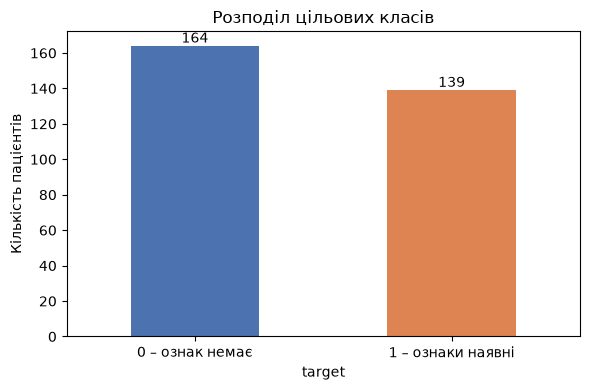

In [9]:
ax = data[TARGET].value_counts().sort_index().plot(
    kind="bar", color=["#4C72B0", "#DD8452"], figsize=(6, 4)
)
ax.set_xticklabels(["0 – ознак немає", "1 – ознаки наявні"], rotation=0)
ax.set_ylabel("Кількість пацієнтів")
ax.set_title("Розподіл цільових класів")
for patch in ax.patches:
    ax.annotate(int(patch.get_height()),
                (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr04_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

#### Типи ознак

У файлі частина категоріальних ознак збережена числовими кодами, тому тип `int`/`float` у pandas
не означає, що ознака кількісна. Наприклад, `cp` = 1, 2, 3, 4 — коди типу болю, а не шкала,
тому до неї застосовується OneHotEncoder, а не StandardScaler.

In [10]:
numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

assert set(numeric_columns + categorical_columns + [TARGET]) == set(data.columns)

print("Унікальні значення категоріальних ознак:")
for column in categorical_columns:
    values = sorted(data[column].dropna().unique().tolist())
    print(f"  {column:8s} {values}")

display(data[numeric_columns].describe().round(2))

Унікальні значення категоріальних ознак:
  sex      [0, 1]
  cp       [1, 2, 3, 4]
  fbs      [0, 1]
  restecg  [0, 1, 2]
  exang    [0, 1]
  slope    [1, 2, 3]
  ca       [0.0, 1.0, 2.0, 3.0]
  thal     [3.0, 6.0, 7.0]


,age,trestbps,chol,thalach,oldpeak
count,303.00,303.00,303.00,303.00,303.00
mean,54.44,131.69,246.69,149.61,1.04
std,9.04,17.60,51.78,22.88,1.16
min,29.00,94.00,126.00,71.00,0.00
25%,48.00,120.00,211.00,133.50,0.00
50%,56.00,130.00,241.00,153.00,0.80
75%,61.00,140.00,275.00,166.00,1.60
max,77.00,200.00,564.00,202.00,6.20


In [11]:
audit = pd.DataFrame(
    {
        "Характеристика": [
            "Кількість об'єктів",
            "Кількість вхідних ознак",
            "Числові ознаки",
            "Категоріальні ознаки",
            "Кількість пропусків",
            "Кількість класів",
            "Позитивний клас"
        ],
        "Значення": [
            data.shape[0],
            data.shape[1] - 1,
            ", ".join(numeric_columns),
            ", ".join(categorical_columns),
            f"{int(missing.sum())} (ca – {int(missing['ca'])}, thal – {int(missing['thal'])})",
            data[TARGET].nunique(),
            f"{POSITIVE_CLASS} – ознаки захворювання наявні"
        ]
    }
)
display(audit)

,Характеристика,Значення
0,Кількість об'єктів,303
1,Кількість вхідних ознак,13
2,Числові ознаки,"age, trestbps, chol, thalach, oldpeak"
3,Категоріальні ознаки,"sex, cp, fbs, restecg, exang, slope, ca, thal"
4,Кількість пропусків,"6 (ca – 4, thal – 2)"
5,Кількість класів,2
6,Позитивний клас,1 – ознаки захворювання наявні


**Результат аудиту.** Набір містить **303 об'єкти** і **13 вхідних ознак** (5 числових і 8 категоріальних).
Є **6 пропусків**: 4 у `ca` і 2 у `thal` (6 рядків); дублікатів немає. Класи майже збалансовані:
164 пацієнти без ознак захворювання (54,13 %) і 139 з ознаками (45,87 %). Ціль містить лише 0 і 1.
Числові ознаки мають дуже різні діапазони (`chol` — сотні, `oldpeak` — одиниці), що важливо для
моделей, чутливих до масштабу. Дані придатні до побудови моделей; пропуски буде заповнено всередині Pipeline.

### 4. Виділення X і y та фіксоване розбиття train/test

Розбиття виконується **один раз** до навчання будь-яких перетворень і надалі не змінюється.
`stratify=y` зберігає співвідношення класів, `random_state=42` забезпечує відтворюваність.

In [12]:
X = data.drop(columns=[TARGET])
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train:", X_train.shape, "  y_train:", y_train.shape)
print("X_test: ", X_test.shape, "  y_test: ", y_test.shape)

X_train: (242, 13)   y_train: (242,)
X_test:  (61, 13)   y_test:  (61,)


In [13]:
split_distribution = pd.DataFrame(
    {
        "усього": y.value_counts().sort_index(),
        "train": y_train.value_counts().sort_index(),
        "test": y_test.value_counts().sort_index(),
        "усього, %": y.value_counts(normalize=True).sort_index().mul(100).round(2),
        "train, %": y_train.value_counts(normalize=True).sort_index().mul(100).round(2),
        "test, %": y_test.value_counts(normalize=True).sort_index().mul(100).round(2)
    }
)
display(split_distribution)

print("Пропусків у X_train:", int(X_train.isna().sum().sum()))
print("Пропусків у X_test:", int(X_test.isna().sum().sum()))

,усього,train,test,"усього, %","train, %","test, %"
target,,,,,,
0,164,131,33,54.13,54.13,54.1
1,139,111,28,45.87,45.87,45.9


Пропусків у X_train: 2
Пропусків у X_test: 4


Навчальна вибірка містить **242 об'єкти** (131 / 111), тестова — **61** (33 / 28); частки класів
у train (54,13 / 45,87 %) і test (54,10 / 45,90 %) практично збігаються з початковими.

> **Тестова вибірка закрита.** До практичної роботи 7 `X_test` і `y_test` не використовуються
> ні для обчислення метрик, ні для вибору алгоритму чи параметрів.

### 5. Єдина схема крос-валідації та метрики

Одна й та сама `StratifiedKFold` використовується для **всіх** алгоритмів мініпроєкту, тому всі
моделі оцінюються на однакових п'яти парах «внутрішній train / валідація».

In [14]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

SCORING = {
    "f1": "f1",
    "roc_auc": "roc_auc",
    "recall": "recall",
    "precision": "precision",
    "accuracy": "accuracy"
}

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_train, y_train), start=1):
    print(
        f"Фолд {fold}: train {len(train_idx)}, validation {len(valid_idx)}, "
        f"частка класу 1 у validation {y_train.iloc[valid_idx].mean():.3f}"
    )

Фолд 1: train 193, validation 49, частка класу 1 у validation 0.469
Фолд 2: train 193, validation 49, частка класу 1 у validation 0.449
Фолд 3: train 194, validation 48, частка класу 1 у validation 0.458
Фолд 4: train 194, validation 48, частка класу 1 у validation 0.458
Фолд 5: train 194, validation 48, частка класу 1 у validation 0.458


In [15]:
IGNORED_WARNINGS = (DeprecationWarning, FutureWarning)


def evaluate_cv(pipeline, model_name, params=""):
    """Однакова оцінка будь-якого Pipeline за cv на X_train, y_train."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring=SCORING,
            error_score="raise"
        )
    messages = sorted(
        {w.category.__name__ for w in caught if not issubclass(w.category, IGNORED_WARNINGS)}
    )
    return {
        "model": model_name,
        "params": params,
        "cv_f1_mean": scores["test_f1"].mean(),
        "cv_f1_std": scores["test_f1"].std(),
        "cv_roc_auc_mean": scores["test_roc_auc"].mean(),
        "cv_roc_auc_std": scores["test_roc_auc"].std(),
        "cv_recall_mean": scores["test_recall"].mean(),
        "cv_precision_mean": scores["test_precision"].mean(),
        "cv_accuracy_mean": scores["test_accuracy"].mean(),
        "fit_time_ms": scores["fit_time"].mean() * 1000,
        "warnings": ", ".join(messages) if messages else "—"
    }


def show(results, columns=None):
    """Таблиця результатів з округленням до 3 знаків."""
    table = pd.DataFrame(results)
    display((table[columns] if columns else table).round(3))
    return table

### 6. Підготовка даних за допомогою Pipeline

- **числові ознаки:** заповнення пропусків медіаною (`SimpleImputer(strategy="median")`) і
  стандартизація `StandardScaler` (або `passthrough` для експериментів без масштабування);
- **категоріальні ознаки:** заповнення найчастішою категорією і `OneHotEncoder(handle_unknown="ignore",
  sparse_output=False)` — нова категорія в test не спричинить помилку, а щільна матриця сумісна з
  GaussianNB, LDA і QDA.

Усі параметри перетворень (медіани, моди, середні, стандартні відхилення, перелік категорій)
навчаються всередині Pipeline лише на train-частині кожного фолду.

In [16]:
def make_onehot():
    """OneHotEncoder із щільним виходом (у старих версіях scikit-learn — sparse=False)."""
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def make_preprocessor(scaler="standard"):
    """ColumnTransformer: scaler = 'standard', 'minmax' або None (passthrough)."""
    if scaler == "standard":
        numeric_scaler = StandardScaler()
    elif scaler == "minmax":
        numeric_scaler = MinMaxScaler()
    else:
        numeric_scaler = "passthrough"

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", numeric_scaler)
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", make_onehot())
    ])
    return ColumnTransformer([
        ("num", numeric_pipeline, numeric_columns),
        ("cat", categorical_pipeline, categorical_columns)
    ])


def make_pipeline(classifier, scaler="standard"):
    return Pipeline([
        ("preprocessor", make_preprocessor(scaler)),
        ("classifier", classifier)
    ])


model_pipeline = make_pipeline(LogisticRegression(max_iter=2000))
print(model_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_un

In [17]:
# Перевірка перетворень: навчаємо препроцесор лише на X_train
preprocessor_check = make_preprocessor().fit(X_train)
X_train_transformed = preprocessor_check.transform(X_train)
feature_names = preprocessor_check.get_feature_names_out()

print("Розмір X_train після перетворення:", X_train_transformed.shape)
print("Пропусків після імпутації:", int(np.isnan(X_train_transformed).sum()))
print("Медіани числових ознак (train):")
print(pd.Series(
    preprocessor_check.named_transformers_["num"].named_steps["imputer"].statistics_,
    index=numeric_columns
))
print("\nОзнаки після OneHotEncoder:", len(feature_names))
print(list(feature_names))

Розмір X_train після перетворення: (242, 28)
Пропусків після імпутації: 0
Медіани числових ознак (train):
age          56.0
trestbps    130.0
chol        244.5
thalach     153.5
oldpeak       0.8
dtype: float64

Ознаки після OneHotEncoder: 28
['num__age', 'num__trestbps', 'num__chol', 'num__thalach', 'num__oldpeak', 'cat__sex_0.0', 'cat__sex_1.0', 'cat__cp_1.0', 'cat__cp_2.0', 'cat__cp_3.0', 'cat__cp_4.0', 'cat__fbs_0.0', 'cat__fbs_1.0', 'cat__restecg_0.0', 'cat__restecg_1.0', 'cat__restecg_2.0', 'cat__exang_0.0', 'cat__exang_1.0', 'cat__slope_1.0', 'cat__slope_2.0', 'cat__slope_3.0', 'cat__ca_0.0', 'cat__ca_1.0', 'cat__ca_2.0', 'cat__ca_3.0', 'cat__thal_3.0', 'cat__thal_6.0', 'cat__thal_7.0']


Після перетворення кожен об'єкт описується **28 ознаками**: 5 стандартизованих числових і 23 бінарні
стовпці one-hot (наприклад, `cp` дає 4 стовпці, `thal` — 3). Пропусків після імпутації немає.
Препроцесор тут навчено лише на `X_train` для перевірки; у CV він щоразу перенавчається всередині Pipeline.

### 7. Логістична регресія: вплив масштабування

Порівнюються два повні Pipeline з однаковою `LogisticRegression(max_iter=2000)` (L2, C = 1, solver lbfgs):
без стандартизації числових ознак (`passthrough`) і зі `StandardScaler`.

In [18]:
scaling_results = []
for scaler, title in ((None, "без стандартизації"), ("standard", "зі StandardScaler")):
    pipeline = make_pipeline(LogisticRegression(max_iter=2000), scaler=scaler)
    result = evaluate_cv(pipeline, "Logistic Regression", title)

    # кількість ітерацій оптимізатора після навчання на всій train-вибірці
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        fitted = clone(pipeline).fit(X_train, y_train)
    result["n_iter_full_train"] = int(fitted.named_steps["classifier"].n_iter_[0])
    scaling_results.append(result)

scaling_table = show(
    scaling_results,
    ["params", "cv_f1_mean", "cv_f1_std", "cv_roc_auc_mean", "cv_roc_auc_std",
     "cv_recall_mean", "n_iter_full_train", "fit_time_ms", "warnings"]
)

,params,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,cv_roc_auc_std,cv_recall_mean,n_iter_full_train,fit_time_ms,warnings
0,без стандартизації,0.825,0.007,0.900,0.016,0.783,1310,148.954,—
1,зі StandardScaler,0.825,0.007,0.902,0.014,0.783,18,13.029,—


In [19]:
# Та сама модель зі стандартним лімітом ітерацій max_iter=100
convergence_check = []
for scaler, title in ((None, "без стандартизації"), ("standard", "зі StandardScaler")):
    convergence_check.append(
        evaluate_cv(make_pipeline(LogisticRegression(max_iter=100), scaler=scaler),
                    "Logistic Regression", f"{title}, max_iter=100")
    )
show(convergence_check, ["params", "cv_f1_mean", "cv_f1_std", "cv_roc_auc_mean", "warnings"]);

,params,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,warnings
0,"без стандартизації, max_iter=100",0.828,0.019,0.901,ConvergenceWarning
1,"зі StandardScaler, max_iter=100",0.825,0.007,0.902,—


**Висновок щодо масштабування.** За якістю обидва варіанти майже однакові: CV F1 = 0,825 ± 0,007,
CV ROC AUC — 0,900 без стандартизації і 0,902 зі стандартизацією. Головна різниця — у **збіжності**:
без масштабування оптимізатору lbfgs на всій train-вибірці знадобилося **1310 ітерацій**, а зі
StandardScaler — лише **18**; навчання без масштабування приблизно в 10 разів довше. Зі стандартним
лімітом `max_iter=100` немасштабована модель не збігається в жодному фолді (`ConvergenceWarning`),
тоді як масштабована збігається без попереджень. Отже, далі логістична регресія використовується
лише зі StandardScaler: результат стабільніший, а коефіцієнти числових ознак стають порівнянними.

### 8. L1- і L2-регуляризація

Перевіряються C = 0,01; 0,1; 1; 10; 100 для L1 і L2. Мале C — сильніша регуляризація, велике — слабша.
Для обох типів використано solver `liblinear`, що підтримує і L1, і L2, тому порівняння чесне.
Параметри обираються лише за CV на train.

In [20]:
SKLEARN_VERSION = tuple(int(part) for part in sklearn.__version__.split(".")[:2])


def make_logreg(penalty, C):
    """LogisticRegression з L1/L2 для різних версій scikit-learn.

    Починаючи з 1.8 параметр penalty застарів: L1 задається l1_ratio=1, L2 — l1_ratio=0.
    """
    if SKLEARN_VERSION >= (1, 8):
        return LogisticRegression(
            l1_ratio=1.0 if penalty == "l1" else 0.0,
            C=C, solver="liblinear", max_iter=2000
        )
    return LogisticRegression(penalty=penalty, C=C, solver="liblinear", max_iter=2000)


C_VALUES = [0.01, 0.1, 1, 10, 100]

logreg_results = []
for penalty in ("l1", "l2"):
    for C in C_VALUES:
        result = evaluate_cv(make_pipeline(make_logreg(penalty, C)), "Logistic Regression",
                             f"penalty={penalty}, C={C}")
        result["penalty"] = penalty
        result["C"] = C
        logreg_results.append(result)

logreg_table = show(
    logreg_results,
    ["penalty", "C", "cv_f1_mean", "cv_f1_std", "cv_roc_auc_mean", "cv_recall_mean",
     "cv_precision_mean", "warnings"]
)

,penalty,C,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,cv_recall_mean,cv_precision_mean,warnings
0,l1,0.01,0.000,0.000,0.500,0.000,0.000,UndefinedMetricWarning
1,l1,0.10,0.793,0.031,0.884,0.747,0.857,—
2,l1,1.00,0.812,0.017,0.907,0.783,0.854,—
3,l1,10.00,0.832,0.011,0.902,0.802,0.868,—
4,l1,100.00,0.836,0.013,0.897,0.802,0.878,—
5,l2,0.01,0.766,0.017,0.889,0.693,0.864,—
6,l2,0.10,0.814,0.030,0.902,0.774,0.868,—
7,l2,1.00,0.825,0.007,0.902,0.783,0.877,—
8,l2,10.00,0.836,0.013,0.900,0.802,0.878,—
9,l2,100.00,0.836,0.013,0.898,0.802,0.878,—


In [21]:
# Найкраща конфігурація: максимальний CV F1, за рівності — більший CV ROC AUC, далі — менше C
logreg_ranked = logreg_table.assign(
    f1_key=logreg_table["cv_f1_mean"].round(4),
    auc_key=logreg_table["cv_roc_auc_mean"].round(4)
).sort_values(["f1_key", "auc_key", "C"], ascending=[False, False, True])

best_logreg_row = logreg_ranked.iloc[0]
BEST_LOGREG = {"penalty": best_logreg_row["penalty"], "C": float(best_logreg_row["C"])}

print("Найкраща логістична регресія за CV:", BEST_LOGREG)
print(f"CV F1 = {best_logreg_row['cv_f1_mean']:.3f} ± {best_logreg_row['cv_f1_std']:.3f}, "
      f"CV ROC AUC = {best_logreg_row['cv_roc_auc_mean']:.3f}")
display(logreg_ranked.head(4)[["penalty", "C", "cv_f1_mean", "cv_f1_std", "cv_roc_auc_mean"]].round(3))

Найкраща логістична регресія за CV: {'penalty': 'l2', 'C': 10.0}
CV F1 = 0.836 ± 0.013, CV ROC AUC = 0.900


,penalty,C,cv_f1_mean,cv_f1_std,cv_roc_auc_mean
8,l2,10.0,0.836,0.013,0.900
9,l2,100.0,0.836,0.013,0.898
4,l1,100.0,0.836,0.013,0.897
3,l1,10.0,0.832,0.011,0.902


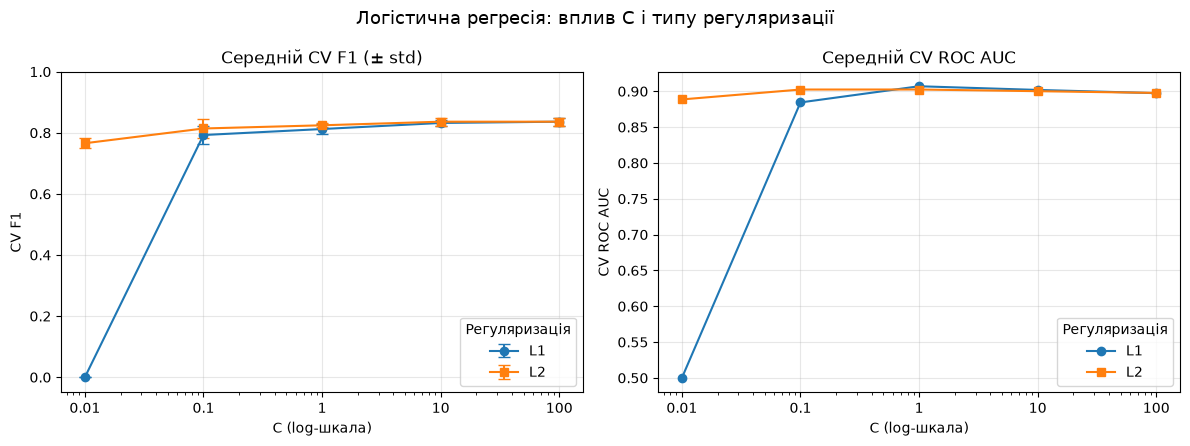

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for penalty, marker in (("l1", "o"), ("l2", "s")):
    part = logreg_table[logreg_table["penalty"] == penalty]
    axes[0].errorbar(part["C"], part["cv_f1_mean"], yerr=part["cv_f1_std"],
                     marker=marker, capsize=4, label=penalty.upper())
    axes[1].plot(part["C"], part["cv_roc_auc_mean"], marker=marker, label=penalty.upper())

for ax, title, ylabel in ((axes[0], "Середній CV F1 (± std)", "CV F1"),
                          (axes[1], "Середній CV ROC AUC", "CV ROC AUC")):
    ax.set_xscale("log")
    ax.set_xticks(C_VALUES)
    ax.set_xticklabels([str(c) for c in C_VALUES])
    ax.set_xlabel("C (log-шкала)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(title="Регуляризація")
axes[0].set_ylim(-0.05, 1.0)
fig.suptitle("Логістична регресія: вплив C і типу регуляризації", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr04_logreg_C.png", dpi=150, bbox_inches="tight")
plt.show()

**Аналіз.** Найсильніша регуляризація шкодить: за **L1, C = 0,01** усі коефіцієнти обнуляються,
модель завжди прогнозує клас 0 (CV F1 = 0, ROC AUC = 0,5, `UndefinedMetricWarning` про відсутність
позитивних прогнозів). L2 за C = 0,01 ще працює, але недонавчена (CV F1 = 0,766, recall 0,693).
Зі зростанням C якість зростає і з C ≈ 10 виходить на плато: **L2, C = 10** і C = 100, а також
L1, C = 100 мають однаковий CV F1 = **0,836 ± 0,013**. За правилом рівності обрано конфігурацію
з більшим CV ROC AUC — **L2, C = 10** (ROC AUC 0,900, recall 0,802, precision 0,878).
Варіанти з C = 10 і C = 100 дають однакові прогнози класу, тобто подальше послаблення регуляризації
вже нічого не змінює; std F1 між фолдами (0,013) невеликий, отже результат стабільний.

### 9. Інтерпретація коефіцієнтів найкращої логістичної регресії

Найкращий Pipeline навчається на всій навчальній вибірці (це ще не фінальна модель — лише для
інтерпретації). Назви ознак отримуються з препроцесора після OneHotEncoder.

In [23]:
best_logreg_pipeline = make_pipeline(make_logreg(BEST_LOGREG["penalty"], BEST_LOGREG["C"]))
best_logreg_pipeline.fit(X_train, y_train)

coefficients = pd.DataFrame(
    {
        # num__age → age, cat__cp_4.0 → cp_4
        "feature": pd.Series(
            best_logreg_pipeline.named_steps["preprocessor"].get_feature_names_out()
        ).str.replace(r"^(num|cat)__", "", regex=True).str.replace(r"\.0$", "", regex=True),
        "coefficient": best_logreg_pipeline.named_steps["classifier"].coef_[0]
    }
)
coefficients["abs_coefficient"] = coefficients["coefficient"].abs()
coefficients["odds_ratio"] = np.exp(coefficients["coefficient"])
coefficients = coefficients.sort_values("abs_coefficient", ascending=False)

top5_coefficients = coefficients.head(5).reset_index(drop=True)
display(top5_coefficients.round(3))

print("Коефіцієнти числових ознак (на одне стандартне відхилення):")
display(coefficients[coefficients["feature"].isin(numeric_columns)].round(3))

,feature,coefficient,abs_coefficient,odds_ratio
0,ca_0,-1.926,1.926,0.146
1,cp_4,1.189,1.189,3.283
2,thal_7,0.978,0.978,2.659
3,cp_1,-0.892,0.892,0.410
4,sex_0,-0.880,0.880,0.415


Коефіцієнти числових ознак (на одне стандартне відхилення):


,feature,coefficient,abs_coefficient,odds_ratio
1,trestbps,0.430,0.430,1.538
3,thalach,-0.392,0.392,0.676
4,oldpeak,0.246,0.246,1.279
2,chol,0.212,0.212,1.236
0,age,-0.112,0.112,0.894


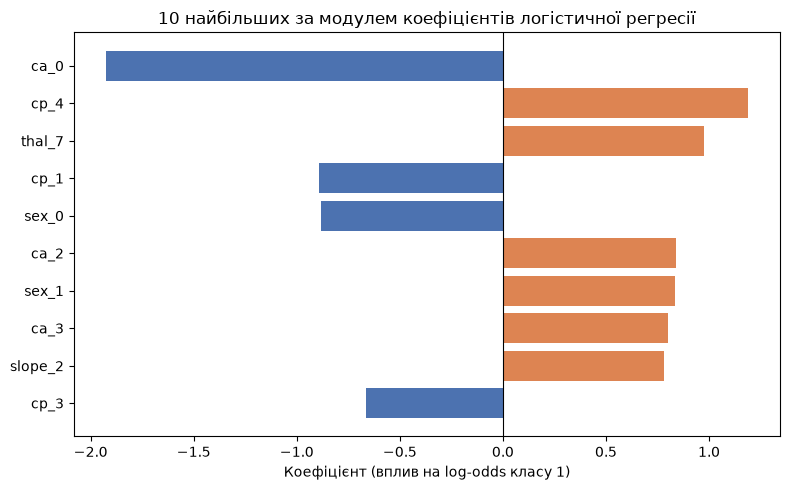

In [24]:
top10 = coefficients.head(10).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top10["feature"], top10["coefficient"],
         color=np.where(top10["coefficient"] > 0, "#DD8452", "#4C72B0"))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Коефіцієнт (вплив на log-odds класу 1)")
plt.title("10 найбільших за модулем коефіцієнтів логістичної регресії")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr04_logreg_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

**Інтерпретація.** П'ять найбільших за модулем коефіцієнтів — усі one-hot-ознаки:

1. `ca_0` (жодної судини, забарвленої під час флюороскопії) — **−1,93**: відсутність уражених судин
   найсильніше зменшує log-odds класу 1 (відношення шансів ≈ 0,15 відносно ca = 1–3);
2. `cp_4` (безсимптомний тип болю в грудях) — **+1,19**: збільшує шанси наявності ознак захворювання (≈ 3,3 раза);
3. `thal_7` (оборотний дефект за таліевим тестом) — **+0,98**: збільшує шанси (≈ 2,7 раза);
4. `cp_1` (типова стенокардія) — **−0,89**: у цьому наборі пов'язана з меншими шансами класу 1, ніж
   безсимптомний біль — це особливість вибірки, а не медичне правило;
5. `sex_0` (жіноча стать) — **−0,88**: шанси класу 1 у жінок цього набору нижчі.

Числові ознаки мають менші коефіцієнти: зростання тиску `trestbps` на одне стандартне відхилення
підвищує log-odds на 0,43, а вищий максимальний пульс `thalach` — знижує (−0,39). Коефіцієнт `age`
слабкий і навіть від'ємний (−0,11): вплив віку вже частково «поглинають» корельовані з ним ознаки
(`ca`, `thalach`), тому коефіцієнт показує зв'язок лише за інших рівних умов.

- додатний коефіцієнт збільшує log-odds позитивного класу за інших рівних умов, від'ємний — зменшує;
- коефіцієнти one-hot-ознак показують зміну log-odds відносно інших категорій тієї самої ознаки,
  а числових — зміну на одне стандартне відхилення (тому їх коректно порівнювати лише після масштабування);
- за слабкої регуляризації (C = 10) і корельованих one-hot-стовпців окремі коефіцієнти можуть бути
  завеликими й нестійкими, тому важливіший їхній знак і порядок, ніж точна величина;
- коефіцієнти показують статистичний зв'язок у цьому наборі й **не доводять причинно-наслідкового
  або медичного впливу**.

### Висновок практичної роботи 4

- Аудит: 303 об'єкти, 13 ознак (5 числових, 8 категоріальних), 6 пропусків у `ca` і `thal`, класи 164 / 139.
- Зафіксовано стратифіковане розбиття 242 / 61 і єдину 5-кратну StratifiedKFold.
- Імпутація, масштабування та one-hot-кодування виконуються всередині Pipeline лише на train-фолдах.
- **Масштабування** майже не змінило якість логістичної регресії (CV F1 0,825 в обох варіантах), але
  прискорило збіжність у ~70 разів за кількістю ітерацій (18 проти 1310) і усунуло `ConvergenceWarning`.
- **Регуляризація:** надто мале C (0,01) спричиняє недонавчання, а для L1 — повне обнулення коефіцієнтів;
  починаючи з C = 10 якість виходить на плато.
- **Найкраща логістична регресія за CV:** L2, C = 10 — CV F1 = 0,836 ± 0,013, CV ROC AUC = 0,900.
- Test-метрики не обчислювалися, `X_test` і `y_test` не використовувалися.

# ЧАСТИНА II. Практична робота 5

## k-NN та ймовірнісні методи класифікації

Використовуються те саме розбиття train/test, той самий препроцесор і та сама `cv`.

### 10. Метод k найближчих сусідів: вплив масштабування

In [25]:
knn_scaling_results = [
    evaluate_cv(make_pipeline(KNeighborsClassifier(n_neighbors=5), scaler=None),
                "k-NN", "k=5, без стандартизації"),
    evaluate_cv(make_pipeline(KNeighborsClassifier(n_neighbors=5), scaler="standard"),
                "k-NN", "k=5, зі StandardScaler"),
    evaluate_cv(make_pipeline(KNeighborsClassifier(n_neighbors=5), scaler="minmax"),
                "k-NN", "k=5, з MinMaxScaler (додатково)")
]
knn_scaling_table = show(
    knn_scaling_results,
    ["params", "cv_f1_mean", "cv_f1_std", "cv_roc_auc_mean", "cv_recall_mean", "cv_accuracy_mean"]
)

,params,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,cv_recall_mean,cv_accuracy_mean
0,"k=5, без стандартизації",0.512,0.013,0.642,0.487,0.574
1,"k=5, зі StandardScaler",0.799,0.043,0.871,0.783,0.822
2,"k=5, з MinMaxScaler (додатково)",0.801,0.048,0.881,0.792,0.822


In [26]:
# Чому без масштабування домінують ознаки з великим діапазоном
print("Діапазони числових ознак на train:")
display(pd.DataFrame({
    "min": X_train[numeric_columns].min(),
    "max": X_train[numeric_columns].max(),
    "std": X_train[numeric_columns].std().round(2)
}))

Діапазони числових ознак на train:


,min,max,std
age,29.0,77.0,9.00
trestbps,94.0,200.0,17.62
chol,126.0,564.0,52.85
thalach,71.0,202.0,22.69
oldpeak,0.0,6.2,1.12


**Аналіз.** Без масштабування k-NN майже не відрізняється від випадкового вгадування:
CV F1 = **0,512**, ROC AUC = 0,642. Евклідова відстань складає квадрати різниць ознак, тому
`chol` (std ≈ 52, діапазон понад 400) і `trestbps`, `thalach` (std ≈ 18–23) повністю визначають
сусідів, а бінарні one-hot-ознаки (різниця 0 або 1) і `oldpeak` практично не впливають. Після
StandardScaler усі числові ознаки мають однаковий масштаб, і якість зростає до **CV F1 = 0,799**,
ROC AUC = 0,871. MinMaxScaler дає близький результат.

### 11. Вибір кількості сусідів

Перевіряються k = 3, 5, 7, 9, 11, 15 (StandardScaler, евклідова відстань).

In [27]:
K_VALUES = [3, 5, 7, 9, 11, 15]

knn_k_results = []
for k in K_VALUES:
    result = evaluate_cv(make_pipeline(KNeighborsClassifier(n_neighbors=k)), "k-NN", f"k={k}")
    result["k"] = k
    knn_k_results.append(result)

knn_k_table = show(
    knn_k_results,
    ["k", "cv_f1_mean", "cv_f1_std", "cv_roc_auc_mean", "cv_recall_mean", "cv_precision_mean"]
)

best_k = int(
    knn_k_table.assign(f1_key=knn_k_table["cv_f1_mean"].round(4))
    .sort_values(["f1_key", "k"], ascending=[False, True])
    .iloc[0]["k"]
)
print("Найкраще k за CV F1:", best_k)

,k,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,cv_recall_mean,cv_precision_mean
0,3,0.804,0.027,0.871,0.801,0.818
1,5,0.799,0.043,0.871,0.783,0.823
2,7,0.794,0.018,0.872,0.766,0.827
3,9,0.787,0.029,0.874,0.756,0.826
4,11,0.779,0.027,0.881,0.738,0.833
5,15,0.765,0.025,0.873,0.721,0.819


Найкраще k за CV F1: 3


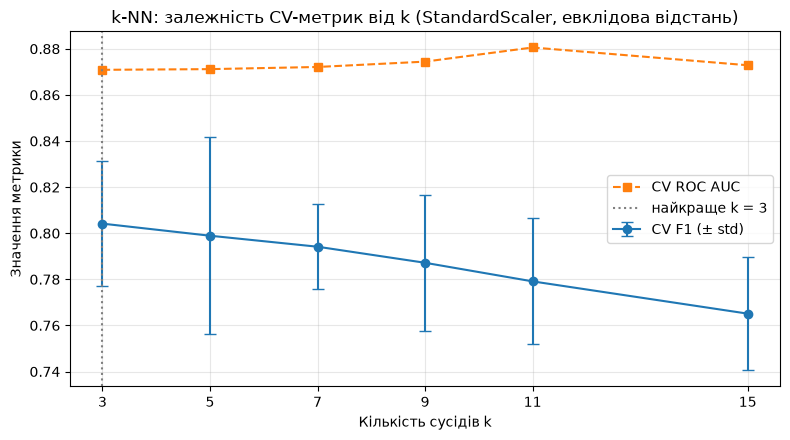

In [28]:
plt.figure(figsize=(8, 4.5))
plt.errorbar(knn_k_table["k"], knn_k_table["cv_f1_mean"], yerr=knn_k_table["cv_f1_std"],
             marker="o", capsize=4, label="CV F1 (± std)")
plt.plot(knn_k_table["k"], knn_k_table["cv_roc_auc_mean"], marker="s", linestyle="--",
         label="CV ROC AUC")
plt.axvline(best_k, color="gray", linestyle=":", label=f"найкраще k = {best_k}")
plt.xticks(K_VALUES)
plt.xlabel("Кількість сусідів k")
plt.ylabel("Значення метрики")
plt.title("k-NN: залежність CV-метрик від k (StandardScaler, евклідова відстань)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr05_knn_k.png", dpi=150, bbox_inches="tight")
plt.show()

**Аналіз.** Найбільший CV F1 має **k = 3** (0,804 ± 0,027); далі F1 поступово спадає до 0,765
за k = 15, бо зростає згладжування і модель втрачає локальну структуру (recall падає з 0,801 до 0,721).
Водночас ROC AUC з ростом k трохи зростає (до 0,881 за k = 11): більше сусідів дає плавніші оцінки
ймовірності, які краще ранжують об'єкти. Різниця F1 між k = 3 і k = 5 (0,005) менша за std між фолдами,
тому вибір k = 3 — вибір за заздалегідь визначеною метрикою, а не суттєва перевага. Дуже мале k
загрожує перенавчанням на шумі, тому стабільність k = 3 перевіряється в підсумковому порівнянні.

### 12. Міри відстані для найкращого k

In [29]:
distance_results = []
for metric_name, params in (
    ("Евклідова", {"metric": "minkowski", "p": 2}),
    ("Мангеттенська", {"metric": "minkowski", "p": 1}),
    ("Мінковського p=3 (додатково)", {"metric": "minkowski", "p": 3})
):
    result = evaluate_cv(
        make_pipeline(KNeighborsClassifier(n_neighbors=best_k, **params)),
        "k-NN", f"k={best_k}, {metric_name}"
    )
    result["distance"] = metric_name
    result["p"] = params["p"]
    distance_results.append(result)

distance_table = show(
    distance_results,
    ["distance", "cv_f1_mean", "cv_f1_std", "cv_roc_auc_mean", "cv_recall_mean"]
)

best_p = int(distance_table.sort_values("cv_f1_mean", ascending=False).iloc[0]["p"])
BEST_KNN = {"n_neighbors": best_k, "p": best_p}
print("Найкраща k-NN за CV:", BEST_KNN)

,distance,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,cv_recall_mean
0,Евклідова,0.804,0.027,0.871,0.801
1,Мангеттенська,0.818,0.030,0.877,0.792
2,Мінковського p=3 (додатково),0.758,0.042,0.839,0.746


Найкраща k-NN за CV: {'n_neighbors': 3, 'p': 1}


**Аналіз.** Для k = 3 мангеттенська відстань (p = 1) дає **CV F1 = 0,818 ± 0,030** і ROC AUC 0,877 —
краще за евклідову (0,804 / 0,871). Мангеттенська відстань сумує модулі різниць, тому одна ознака з
великим відхиленням менше домінує, а внесок численних бінарних one-hot-ознак стає відносно вагомішим.
Мінковського p = 3 ще більше підсилює найбільшу різницю і працює гірше. **Найкраща k-NN: k = 3,
мангеттенська відстань.**

### 13. Імовірнісні методи

#### 13.1. Gaussian Naive Bayes: описовий аналіз розподілів

GaussianNB припускає, що ознаки **умовно незалежні** за відомого класу, а кожна ознака в межах класу
має **нормальний розподіл**. Нижче — розподіли трьох числових ознак окремо для кожного класу
(лише train; це описовий аналіз, а не підстава для перегляду test).

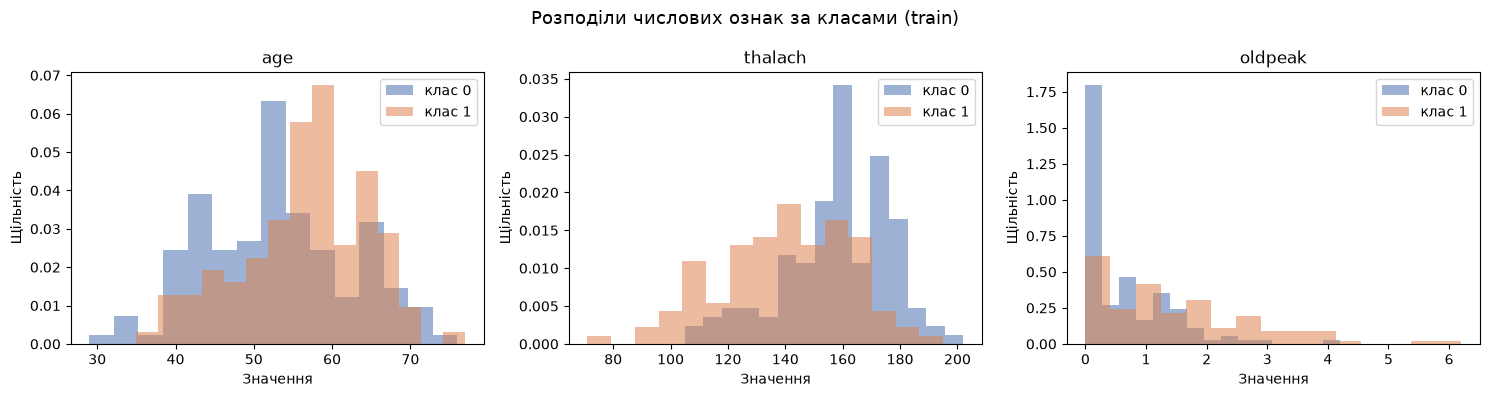

age             thalach              oldpeak            
         mean   std  skew    mean    std  skew    mean   std  skew
target                                                            
0       52.82  9.41  0.10  158.50  18.60 -0.62    0.59  0.76  1.60
1       56.59  8.06 -0.45  139.89  23.02 -0.34    1.48  1.28  1.02

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["age", "thalach", "oldpeak"]):
    for cls, color, label in ((0, "#4C72B0", "клас 0"), (1, "#DD8452", "клас 1")):
        values = X_train.loc[y_train == cls, column]
        ax.hist(values, bins=15, alpha=0.55, color=color, label=label, density=True)
    ax.set_title(column)
    ax.set_xlabel("Значення")
    ax.set_ylabel("Щільність")
    ax.legend()
fig.suptitle("Розподіли числових ознак за класами (train)", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr05_gnb_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

display(
    X_train.assign(target=y_train)
    .groupby("target")[["age", "thalach", "oldpeak"]]
    .agg(["mean", "std", "skew"])
    .round(2)
)

**Аналіз припущень.** `age` і `thalach` у кожному класі близькі до нормального розподілу, а їхні
середні помітно зсунуті: у класу 1 пацієнти старші, а максимальний пульс нижчий. `oldpeak` має
сильну правосторонню асиметрію з піком у нулі (особливо в класу 0) — нормальність порушено.
Крім того, після one-hot-кодування більшість ознак бінарні, а стовпці однієї категорії взаємно
залежні (їхня сума дорівнює 1), тож припущення умовної незалежності свідомо порушується.
GaussianNB попри це може працювати як простий базовий імовірнісний класифікатор.

#### 13.2. GaussianNB, LDA і QDA за однаковою CV

- **LDA** використовує спільну коваріаційну матрицю для класів і формує лінійну межу;
- **QDA** використовує окрему коваріаційну матрицю для кожного класу (нелінійна межа), має більше
  параметрів і потребує більше даних.

In [31]:
probabilistic_results = [
    evaluate_cv(make_pipeline(GaussianNB()), "GaussianNB", "—"),
    evaluate_cv(make_pipeline(LinearDiscriminantAnalysis()), "LDA", "solver=svd")
]
show(probabilistic_results,
     ["model", "cv_f1_mean", "cv_f1_std", "cv_roc_auc_mean", "cv_recall_mean",
      "cv_precision_mean", "warnings"]);

,model,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,cv_recall_mean,cv_precision_mean,warnings
0,GaussianNB,0.749,0.021,0.877,0.846,0.705,—
1,LDA,0.813,0.026,0.899,0.766,0.873,—


#### 13.3. Стабільність QDA і параметр reg_param

QDA оцінює для кожного класу коваріаційну матрицю 28 × 28 за ~90–105 об'єктами фолду. Після
one-hot-кодування стовпці однієї ознаки лінійно залежні, а рідкісні категорії в межах класу можуть
бути константними — матриця стає виродженою. `reg_param` зсуває оцінку до одиничної:
Σ̂ = (1 − r)·Σ + r·I. Обов'язково перевіряються r = 0; 0,01; 0,1, додатково — 0,3; 0,5; 0,7; 1,0.

In [32]:
QDA_REG_PARAMS = [0.0, 0.01, 0.1, 0.3, 0.5, 0.7, 1.0]

qda_results = []
for reg_param in QDA_REG_PARAMS:
    pipeline = make_pipeline(QuadraticDiscriminantAnalysis(reg_param=reg_param))
    try:
        result = evaluate_cv(pipeline, "QDA", f"reg_param={reg_param}")
        result["status"] = "працює" if result["warnings"] == "—" else "попередження"
    except Exception as error:  # вироджена коваріаційна матриця
        message = str(error).strip().splitlines()[-1]
        print(f"reg_param={reg_param}: {type(error).__name__}: {message[:160]}")
        result = {"model": "QDA", "params": f"reg_param={reg_param}",
                  "warnings": type(error).__name__, "status": "помилка навчання"}
    result["reg_param"] = reg_param
    qda_results.append(result)

qda_table = show(
    qda_results,
    ["reg_param", "status", "cv_f1_mean", "cv_f1_std", "cv_roc_auc_mean", "cv_recall_mean", "warnings"]
)

reg_param=0.0: LinAlgError: The covariance matrix of class 0 is not full rank. Increase the value of `reg_param` to reduce the collinearity.


,reg_param,status,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,cv_recall_mean,warnings
0,0.00,помилка навчання,NaN,NaN,NaN,NaN,LinAlgError
1,0.01,працює,0.771,0.044,0.834,0.774,—
2,0.10,працює,0.796,0.027,0.868,0.774,—
3,0.30,працює,0.792,0.032,0.883,0.756,—
4,0.50,працює,0.799,0.029,0.888,0.756,—
5,0.70,працює,0.802,0.045,0.885,0.756,—
6,1.00,працює,0.772,0.045,0.872,0.738,—


Найкращий reg_param для QDA за CV F1: 0.7


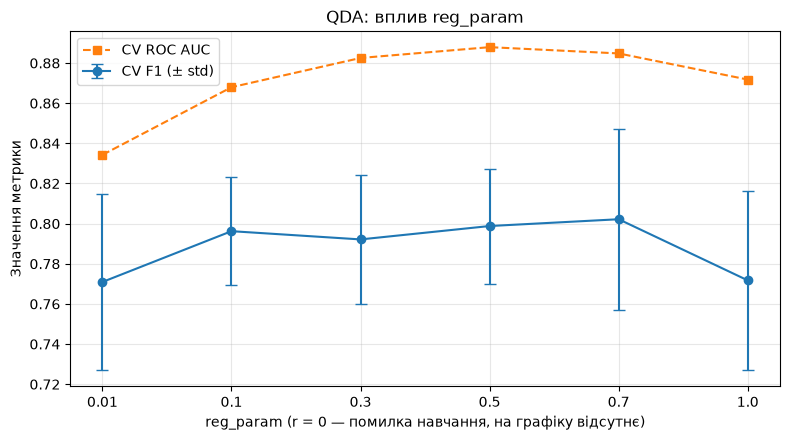

In [33]:
qda_ok = qda_table.dropna(subset=["cv_f1_mean"])
best_qda_reg = float(
    qda_ok.assign(f1_key=qda_ok["cv_f1_mean"].round(4))
    .sort_values(["f1_key", "reg_param"], ascending=[False, True])
    .iloc[0]["reg_param"]
)
print("Найкращий reg_param для QDA за CV F1:", best_qda_reg)

plt.figure(figsize=(8, 4.5))
plt.errorbar(qda_ok["reg_param"].astype(str), qda_ok["cv_f1_mean"], yerr=qda_ok["cv_f1_std"],
             marker="o", capsize=4, label="CV F1 (± std)")
plt.plot(qda_ok["reg_param"].astype(str), qda_ok["cv_roc_auc_mean"], marker="s",
         linestyle="--", label="CV ROC AUC")
plt.xlabel("reg_param (r = 0 — помилка навчання, на графіку відсутнє)")
plt.ylabel("Значення метрики")
plt.title("QDA: вплив reg_param")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr05_qda_reg_param.png", dpi=150, bbox_inches="tight")
plt.show()

**Стабільність QDA.** Без регуляризації (`reg_param = 0`) QDA **не навчається**: scikit-learn
повідомляє, що коваріаційна матриця класу 0 не має повного рангу (`LinAlgError`; у старіших версіях
замість помилки виводиться попередження `Variables are collinear`). Причина — one-hot-стовпці, що в
сумі дають 1, і категорії, які всередині класу не змінюються. З `reg_param = 0,01` модель уже
навчається, але слабко й нестабільно (CV F1 0,771 ± 0,044, ROC AUC 0,834); зі зростанням r якість
зростає, максимум CV F1 = **0,802 ± 0,045** за r = 0,7, а за r = 1,0 знову знижується (модель
перетворюється на класифікатор за відстанню до середніх). Навіть найкращий варіант має найбільший
std між фолдами серед імовірнісних моделей, тож QDA тут **умовно стабільна**: працює лише з сильною
регуляризацією, і цей результат зафіксовано, а не приховано.

### 14. Позавибіркові ймовірності для кількох train-об'єктів

`cross_val_predict(..., method="predict_proba")` для кожного об'єкта train повертає ймовірність від
моделі, навченої **без** цього об'єкта (out-of-fold, OOF). Test не використовується.

In [34]:
prob_models = {
    "GaussianNB": make_pipeline(GaussianNB()),
    "LDA": make_pipeline(LinearDiscriminantAnalysis()),
    "QDA": make_pipeline(QuadraticDiscriminantAnalysis(reg_param=best_qda_reg))
}

oof_probabilities = {}
for name, pipeline in prob_models.items():
    oof_probabilities[name] = cross_val_predict(
        pipeline, X_train, y_train, cv=cv, method="predict_proba"
    )[:, 1]

sample_index = pd.concat([
    y_train[y_train == 0].head(4),
    y_train[y_train == 1].head(4)
]).index

oof_table = pd.DataFrame(
    {"справжній клас": y_train.loc[sample_index]}
)
for name, probabilities in oof_probabilities.items():
    oof_table[f"{name} OOF P(1)"] = pd.Series(probabilities, index=y_train.index).loc[sample_index]
oof_table.index.name = "об'єкт train"
display(oof_table.round(3))

,справжній клас,GaussianNB OOF P(1),LDA OOF P(1),QDA OOF P(1)
об'єкт train,,,,
208,0,0.000,0.021,0.060
167,0,0.000,0.473,0.245
105,0,0.434,0.159,0.164
70,0,0.000,0.008,0.090
180,1,1.000,0.906,0.487
297,1,1.000,0.618,0.766
120,1,1.000,0.980,0.735
55,1,1.000,0.998,0.995


**Аналіз OOF-ймовірностей.** Для більшості об'єктів усі три моделі погоджуються щодо класу,
але відрізняються впевненістю. **GaussianNB** майже завжди видає крайні значення 0,000 або 1,000 —
наслідок «наївного» множення правдоподібностей багатьох залежних one-hot-ознак; її ймовірності погано
калібровані. **LDA** дає помірніші оцінки (наприклад, 0,473 для об'єкта 167 класу 0 — модель сумнівається),
а **QDA** з сильною регуляризацією ще обережніша (0,487 для об'єкта 180 класу 1 — майже на межі).
Об'єкт 105 класу 0 GaussianNB оцінює в 0,434, тоді як LDA і QDA — у 0,16.

### 15. Порівняння k-NN і ймовірнісних моделей

In [35]:
knn_best_result = evaluate_cv(
    make_pipeline(KNeighborsClassifier(**BEST_KNN)),
    "k-NN", f"n_neighbors={BEST_KNN['n_neighbors']}, p={BEST_KNN['p']}"
)
qda_best_result = evaluate_cv(
    make_pipeline(QuadraticDiscriminantAnalysis(reg_param=best_qda_reg)),
    "QDA", f"reg_param={best_qda_reg}"
)
pr05_table = show(
    [knn_best_result] + probabilistic_results + [qda_best_result],
    ["model", "params", "cv_f1_mean", "cv_f1_std", "cv_roc_auc_mean", "cv_recall_mean",
     "cv_precision_mean", "fit_time_ms"]
)

prob_only = pr05_table[pr05_table["model"] != "k-NN"]
best_prob_name = prob_only.sort_values("cv_f1_mean", ascending=False).iloc[0]["model"]
print("Найкраща ймовірнісна модель за CV F1:", best_prob_name)

,model,params,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,cv_recall_mean,cv_precision_mean,fit_time_ms
0,k-NN,"n_neighbors=3, p=1",0.818,0.030,0.877,0.792,0.853,9.587
1,GaussianNB,—,0.749,0.021,0.877,0.846,0.705,11.092
2,LDA,solver=svd,0.813,0.026,0.899,0.766,0.873,10.937
3,QDA,reg_param=0.7,0.802,0.045,0.885,0.756,0.862,10.299


Найкраща ймовірнісна модель за CV F1: LDA


### Висновок практичної роботи 5

- **Масштаб** для k-NN критичний: без стандартизації CV F1 = 0,512 (ознаки `chol`, `trestbps`, `thalach`
  домінують у відстані), зі StandardScaler — 0,799.
- **Кількість сусідів:** найкраще k = 3 (CV F1 0,804); більші k згладжують межу й знижують recall.
- **Міра відстані:** мангеттенська краща за евклідову (0,818 проти 0,804). Найкраща k-NN — k = 3, p = 1:
  CV F1 = 0,818 ± 0,030, ROC AUC = 0,877.
- **GaussianNB** має найвищий recall (0,846), але низьку precision (0,705) і найнижчий F1 (0,749): припущення
  незалежності й нормальності для one-hot-ознак і `oldpeak` порушені.
- **LDA** — найкраща і найстабільніша ймовірнісна модель: CV F1 = 0,813 ± 0,026, ROC AUC = 0,899.
- **QDA** без регуляризації не навчається (вироджена коваріаційна матриця), з reg_param = 0,7 досягає
  CV F1 0,802, але з найбільшим розкидом (std 0,045).
- k, міра відстані та reg_param обрані за CV; `X_test` і `y_test` не використовувалися.

# ЧАСТИНА III. Практична робота 6

## Метод опорних векторів і пошук гіперпараметрів

### 16. Лінійна SVM

SVM навчається на масштабованих ознаках усередині того самого Pipeline. Параметр **C** визначає
компроміс між шириною розділювальної смуги та штрафом за помилки на навчальних даних: мале C —
ширша смуга й більше допущених помилок (сильніша регуляризація), велике C — вужча смуга і ризик
підлаштування під окремі об'єкти.

In [36]:
linear_svm_results = []
for C in [0.1, 1, 10]:
    result = evaluate_cv(make_pipeline(SVC(kernel="linear", C=C)), "Linear SVM", f"C={C}")
    result["C"] = C
    linear_svm_results.append(result)

linear_svm_table = show(
    linear_svm_results,
    ["C", "cv_f1_mean", "cv_f1_std", "cv_roc_auc_mean", "cv_recall_mean", "cv_precision_mean",
     "fit_time_ms"]
)

,C,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,cv_recall_mean,cv_precision_mean,fit_time_ms
0,0.1,0.796,0.054,0.905,0.738,0.880,20.733
1,1.0,0.803,0.031,0.898,0.775,0.838,11.933
2,10.0,0.800,0.026,0.897,0.775,0.831,15.773


Для лінійної SVM найкращий CV F1 має **C = 1** (0,803 ± 0,031); за C = 0,1 модель має найвищий
ROC AUC (0,905), але нижчий recall (0,738), бо широка смуга зсуває межу на користь класу 0.
ROC AUC для SVM обчислюється за значеннями `decision_function`, тому `probability=True` не потрібне.

### 17. SVM із RBF-ядром

- **C** контролює силу штрафу за помилки;
- **gamma** контролює локальність впливу окремих навчальних об'єктів: мале gamma — широкий вплив і
  гладка межа (ризик недонавчання), велике gamma — вплив лише найближчих точок і складна межа
  (ризик перенавчання);
- `gamma="scale"` = 1 / (кількість ознак · дисперсія X) обчислюється за даними фолду.

In [37]:
X_train_prepared = make_preprocessor().fit_transform(X_train)
gamma_scale = 1 / (X_train_prepared.shape[1] * X_train_prepared.var())
print(f"gamma='scale' для перетвореного train ≈ {gamma_scale:.4f} "
      f"({X_train_prepared.shape[1]} ознак, дисперсія {X_train_prepared.var():.3f})")

gamma='scale' для перетвореного train ≈ 0.0933 (28 ознак, дисперсія 0.383)


### 18. Пошук гіперпараметрів GridSearchCV

Сітка коректна: для лінійного ядра `gamma` не задається, для RBF перебираються C і gamma.
GridSearchCV використовує ту саму `cv`, основну метрику F1 (`refit="f1"`) і лише `X_train`, `y_train`.

In [38]:
param_grid = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1, 1, 10]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", 0.01, 0.1]
    }
]

svm_search = GridSearchCV(
    estimator=make_pipeline(SVC()),
    param_grid=param_grid,
    scoring=SCORING,
    refit="f1",
    cv=cv,
    n_jobs=1
)

start = time.perf_counter()
svm_search.fit(X_train, y_train)
print(f"Перевірено конфігурацій: {len(svm_search.cv_results_['params'])}, "
      f"час пошуку: {time.perf_counter() - start:.1f} с")
print("Найкращі параметри:", svm_search.best_params_)
print(f"Найкращий CV F1: {svm_search.best_score_:.3f}")

Перевірено конфігурацій: 12, час пошуку: 1.7 с
Найкращі параметри: {'classifier__C': 10, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}
Найкращий CV F1: 0.827


In [39]:
svm_cv = pd.DataFrame(svm_search.cv_results_)
svm_cv["kernel"] = svm_cv["param_classifier__kernel"]
svm_cv["C"] = svm_cv["param_classifier__C"]
svm_cv["gamma"] = svm_cv["param_classifier__gamma"].fillna("—").astype(str)

svm_top = (
    svm_cv.sort_values(["rank_test_f1", "mean_test_roc_auc"], ascending=[True, False])
    [["rank_test_f1", "kernel", "C", "gamma", "mean_test_f1", "std_test_f1",
      "mean_test_roc_auc", "mean_test_recall", "mean_fit_time"]]
    .head(6)
    .reset_index(drop=True)
)
svm_top["mean_fit_time"] = svm_top["mean_fit_time"] * 1000
svm_top = svm_top.rename(columns={"mean_fit_time": "fit_time_ms"})
display(svm_top.round(3))

,rank_test_f1,kernel,C,gamma,mean_test_f1,std_test_f1,mean_test_roc_auc,mean_test_recall,fit_time_ms
0,1,rbf,10.0,0.01,0.827,0.033,0.897,0.783,10.423
1,2,linear,1.0,—,0.803,0.031,0.898,0.775,11.332
2,3,linear,10.0,—,0.800,0.026,0.897,0.775,15.981
3,4,linear,0.1,—,0.796,0.054,0.905,0.738,11.269
4,5,rbf,1.0,0.01,0.795,0.029,0.896,0.756,9.799
5,6,rbf,1.0,scale,0.789,0.027,0.888,0.765,11.713


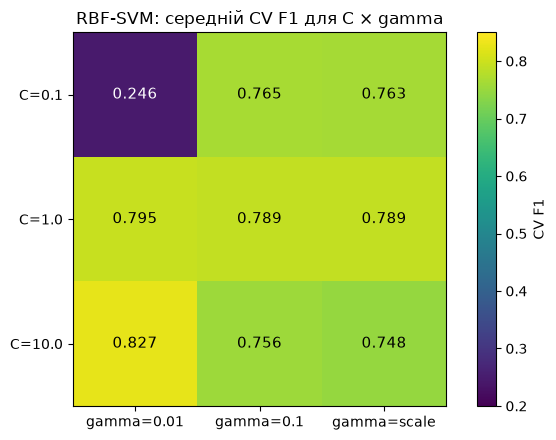

In [40]:
rbf_grid = (
    svm_cv[svm_cv["kernel"] == "rbf"]
    .pivot(index="C", columns="gamma", values="mean_test_f1")
    [["0.01", "0.1", "scale"]]
)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
image = ax.imshow(rbf_grid.values, cmap="viridis", vmin=0.2, vmax=0.85)
ax.set_xticks(range(rbf_grid.shape[1]))
ax.set_xticklabels([f"gamma={g}" for g in rbf_grid.columns])
ax.set_yticks(range(rbf_grid.shape[0]))
ax.set_yticklabels([f"C={c}" for c in rbf_grid.index])
for i in range(rbf_grid.shape[0]):
    for j in range(rbf_grid.shape[1]):
        value = rbf_grid.values[i, j]
        ax.text(j, i, f"{value:.3f}", ha="center", va="center",
                color="white" if value < 0.6 else "black", fontsize=11)
plt.colorbar(image, ax=ax, label="CV F1")
ax.set_title("RBF-SVM: середній CV F1 для C × gamma")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr06_rbf_grid.png", dpi=150, bbox_inches="tight")
plt.show()

**Аналіз сітки.** Найкраща конфігурація — **RBF, C = 10, gamma = 0,01**: CV F1 = **0,827 ± 0,033**,
ROC AUC 0,897, recall 0,783. Вплив параметрів добре видно на тепловій карті:

- за **C = 0,1 і gamma = 0,01** межа надто гладка, а штраф слабкий — модель майже завжди прогнозує
  клас 0 (recall 0,145, F1 0,246) — недонавчання;
- `gamma="scale"` тут ≈ 0,1, тому стовпці `scale` і `0,1` майже однакові; за **C = 10** і великої gamma
  F1 падає до ~0,75, ROC AUC — до 0,823: складна локальна межа підлаштовується під train-фолди — перенавчання;
- найкраще поєднання — **сильний штраф (C = 10) і широке ядро (gamma = 0,01)**: межа гнучка, але гладка,
  майже лінійна.

### 19. Порівняння linear і RBF SVM

In [41]:
best_linear_C = float(
    svm_cv[svm_cv["kernel"] == "linear"].sort_values("rank_test_f1").iloc[0]["C"]
)
BEST_SVM = {
    key.replace("classifier__", ""): value for key, value in svm_search.best_params_.items()
}
print("Найкраща SVM за CV:", BEST_SVM)

svm_compare = show(
    [
        evaluate_cv(make_pipeline(SVC(kernel="linear", C=best_linear_C)),
                    "Linear SVM", f"C={best_linear_C}"),
        evaluate_cv(make_pipeline(SVC(**BEST_SVM)),
                    "RBF SVM", ", ".join(f"{k}={v}" for k, v in BEST_SVM.items() if k != "kernel"))
    ],
    ["model", "params", "cv_f1_mean", "cv_f1_std", "cv_roc_auc_mean", "cv_roc_auc_std",
     "cv_recall_mean", "fit_time_ms"]
)

Найкраща SVM за CV: {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}


,model,params,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,cv_roc_auc_std,cv_recall_mean,fit_time_ms
0,Linear SVM,C=1.0,0.803,0.031,0.898,0.015,0.775,12.150
1,RBF SVM,"C=10, gamma=0.01",0.827,0.033,0.897,0.018,0.783,11.472


### Висновок практичної роботи 6

- Linear SVM: найкраще **C = 1** — CV F1 = 0,803 ± 0,031, ROC AUC 0,898.
- RBF SVM: найкраще **C = 10, gamma = 0,01** — CV F1 = 0,827 ± 0,033, ROC AUC 0,897, recall 0,783.
- RBF-ядро виграло 0,024 за F1 за практично однакового ROC AUC і часу навчання (~10 мс на фолд);
  це більше за різницю між сусідніми C, але порівнянно з std між фолдами.
- Мале C разом із малою gamma дає недонавчання (F1 0,246), велике C з великою gamma — перенавчання
  (F1 ≈ 0,75); найкраща модель має сильний штраф і широке ядро, тобто майже лінійну межу.
- **Найкраща SVM за CV: RBF, C = 10, gamma = 0,01.** GridSearchCV працював лише з `X_train`, `y_train`;
  test-метрики не обчислювалися.

# ЧАСТИНА IV. Практична робота 7

## Порівняння моделей, фінальне тестування і збереження Pipeline

### 20. Кандидати та єдина таблиця CV-порівняння

Для кожного алгоритму береться найкраща конфігурація з робіт 4–6. Усі кандидати оцінюються ще раз
однаковою функцією `evaluate_cv` на тих самих фолдах. Таблиця містить **лише CV-метрики**.

In [42]:
candidates = {
    "Logistic Regression": (
        make_pipeline(make_logreg(BEST_LOGREG["penalty"], BEST_LOGREG["C"])),
        f"penalty={BEST_LOGREG['penalty']}, C={BEST_LOGREG['C']:g}, solver=liblinear"
    ),
    "k-NN": (
        make_pipeline(KNeighborsClassifier(**BEST_KNN)),
        f"n_neighbors={BEST_KNN['n_neighbors']}, metric=minkowski, p={BEST_KNN['p']}"
    ),
    "GaussianNB": (make_pipeline(GaussianNB()), "—"),
    "LDA": (make_pipeline(LinearDiscriminantAnalysis()), "solver=svd"),
    "QDA": (
        make_pipeline(QuadraticDiscriminantAnalysis(reg_param=best_qda_reg)),
        f"reg_param={best_qda_reg:g}"
    ),
    "SVM": (
        make_pipeline(SVC(**BEST_SVM)),
        ", ".join(f"{k}={v}" for k, v in BEST_SVM.items())
    )
}

comparison_rows = [evaluate_cv(pipeline, name, params)
                   for name, (pipeline, params) in candidates.items()]

cv_comparison = (
    pd.DataFrame(comparison_rows)
    .rename(columns={"params": "best_params"})
    [["model", "best_params", "cv_f1_mean", "cv_f1_std", "cv_recall_mean", "cv_precision_mean",
      "cv_roc_auc_mean", "cv_roc_auc_std", "cv_accuracy_mean", "fit_time_ms", "warnings"]]
    .sort_values("cv_f1_mean", ascending=False)
    .reset_index(drop=True)
)
display(cv_comparison.round(3))

,model,best_params,cv_f1_mean,cv_f1_std,cv_recall_mean,cv_precision_mean,cv_roc_auc_mean,cv_roc_auc_std,cv_accuracy_mean,fit_time_ms,warnings
0,Logistic Regression,"penalty=l2, C=10, solver=liblinear",0.836,0.013,0.802,0.878,0.900,0.013,0.855,11.126,—
1,SVM,"C=10, gamma=0.01, kernel=rbf",0.827,0.033,0.783,0.885,0.897,0.018,0.851,11.163,—
2,k-NN,"n_neighbors=3, metric=minkowski, p=1",0.818,0.030,0.792,0.853,0.877,0.033,0.839,10.259,—
3,LDA,solver=svd,0.813,0.026,0.766,0.873,0.899,0.016,0.839,11.420,—
4,QDA,reg_param=0.7,0.802,0.045,0.756,0.862,0.885,0.040,0.831,10.157,—
5,GaussianNB,—,0.749,0.021,0.846,0.705,0.877,0.021,0.744,11.279,—


In [43]:
cv_comparison.round(4).to_csv(CV_COMPARISON_PATH, index=False)
print("Збережено:", CV_COMPARISON_PATH.relative_to(PROJECT_DIR))
assert not any(column.startswith("test") for column in cv_comparison.columns)

Збережено: reports\cv_model_comparison.csv


### 21. Крос-валідаційні ROC-криві кандидатів

ROC-криві будуються за позавибірковими прогнозами `cross_val_predict` на train: для моделей з
`predict_proba` — ймовірність класу 1, для SVM — `decision_function`.

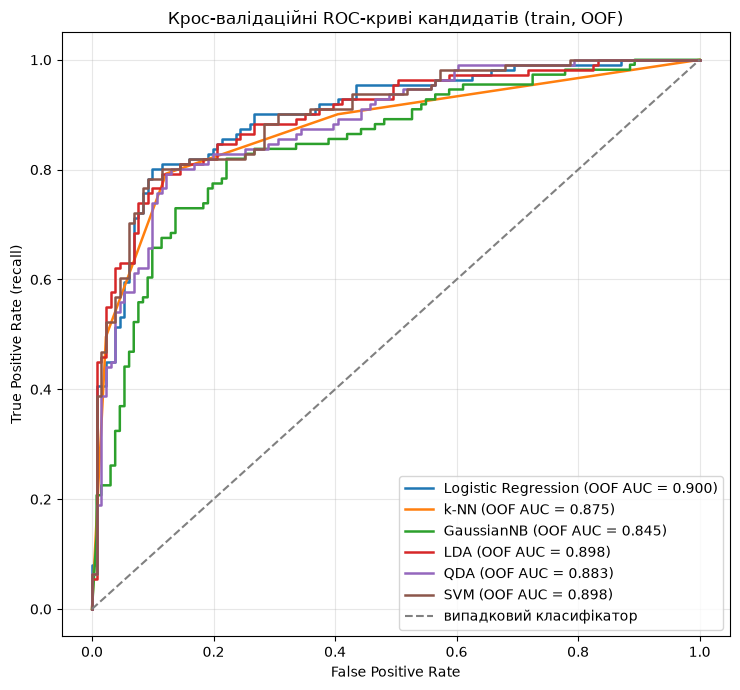

,OOF ROC AUC
Logistic Regression,0.900
SVM,0.898
LDA,0.898
QDA,0.883
k-NN,0.875
GaussianNB,0.845


In [44]:
oof_scores = {}
for name, (pipeline, _) in candidates.items():
    method = "decision_function" if name == "SVM" else "predict_proba"
    scores = cross_val_predict(pipeline, X_train, y_train, cv=cv, method=method)
    oof_scores[name] = scores if method == "decision_function" else scores[:, 1]

fig, ax = plt.subplots(figsize=(7.5, 7))
for name, scores in oof_scores.items():
    fpr, tpr, _ = roc_curve(y_train, scores, pos_label=POSITIVE_CLASS)
    ax.plot(fpr, tpr, linewidth=1.8,
            label=f"{name} (OOF AUC = {roc_auc_score(y_train, scores):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="випадковий класифікатор")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (recall)")
ax.set_title("Крос-валідаційні ROC-криві кандидатів (train, OOF)")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr07_cv_roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

oof_auc = pd.Series({name: roc_auc_score(y_train, s) for name, s in oof_scores.items()},
                    name="OOF ROC AUC").sort_values(ascending=False)
display(oof_auc.round(3).to_frame())

**Аналіз ROC-кривих.** Крива ближче до лівого верхнього кута і більша площа під нею означають кращу
здатність моделі ставити хворих пацієнтів вище за здорових. Найвищий OOF ROC AUC має **логістична
регресія (0,900)**, майже однакові з нею SVM і LDA (0,898); далі QDA (0,883), k-NN (0,875) і GaussianNB
(0,845). Криві трьох лінійних моделей майже збігаються. Крива k-NN ступінчаста, бо за k = 3 оцінка
ймовірності набуває лише значень 0, 1/3, 2/3 і 1. OOF AUC GaussianNB (0,845) помітно нижчий за середній
AUC за фолдами (0,877): її крайні ймовірності з різних фолдів погано порівнянні між собою.
Ці криві — навчальне порівняння на train; незалежна ROC-крива будується лише для фінальної моделі на test.

### 22. Крос-валідаційні матриці помилок

Матриці побудовано за OOF-прогнозами класу (`cross_val_predict`, method="predict") для найкращої
логістичної регресії, k-NN, імовірнісної моделі та SVM.

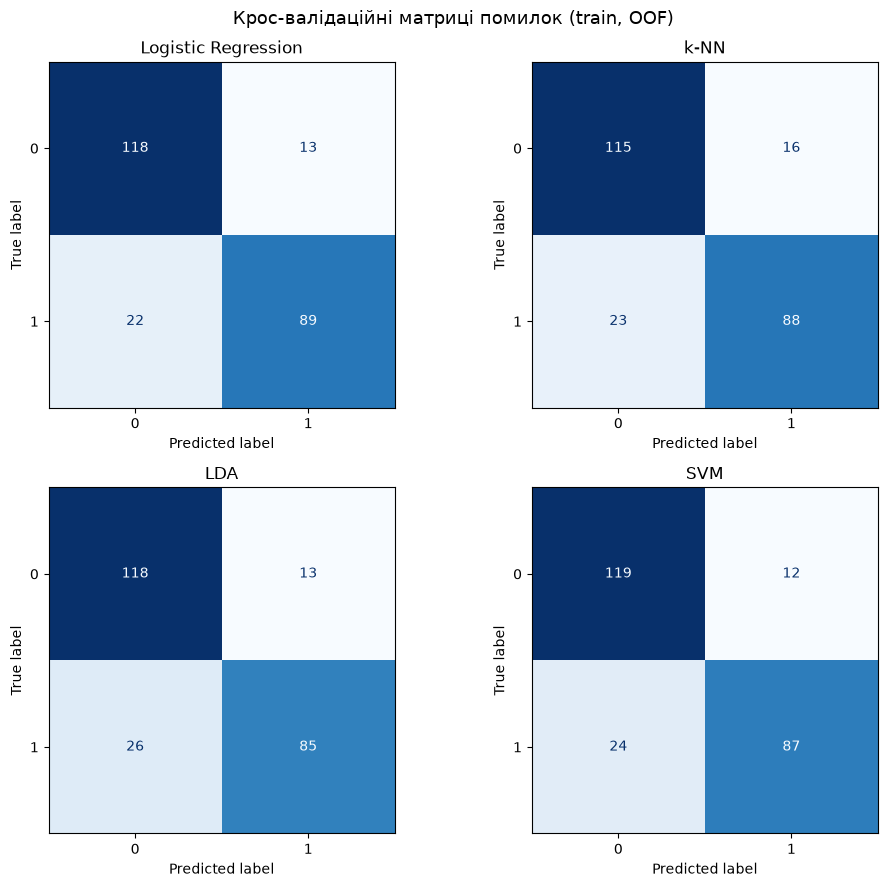

,model,TN,FP,FN,TP,правильних,recall класу 1
0,Logistic Regression,118,13,22,89,207,0.802
1,k-NN,115,16,23,88,203,0.793
2,LDA,118,13,26,85,203,0.766
3,SVM,119,12,24,87,206,0.784


In [45]:
cm_models = ["Logistic Regression", "k-NN", best_prob_name, "SVM"]

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
cm_summary = []
for ax, name in zip(axes.ravel(), cm_models):
    predictions = cross_val_predict(candidates[name][0], X_train, y_train, cv=cv)
    matrix = confusion_matrix(y_train, predictions, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["0", "1"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(name)
    tn, fp, fn, tp = matrix.ravel()
    cm_summary.append({"model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                       "правильних": tn + tp, "recall класу 1": tp / (tp + fn)})
fig.suptitle("Крос-валідаційні матриці помилок (train, OOF)", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr07_cv_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

display(pd.DataFrame(cm_summary).round(3))

**Аналіз матриць помилок (242 об'єкти train).** Найбільше правильних прогнозів і найменше пропущених
хворих має **логістична регресія**: 207 правильних, FN = 22, FP = 13, recall класу 1 = 0,802. SVM має 206
правильних і найменше хибних тривог (FP = 12), але пропускає більше хворих (FN = 24). k-NN дає FN = 23 і
найбільше хибних тривог (FP = 16), LDA пропускає найбільше позитивних об'єктів (FN = 26, recall 0,766).
В усіх моделей FN більше, ніж FP: за порогу 0,5 моделі частіше помиляються на користь класу 0,
що для медичного скринінгу є важливим обмеженням.

### 23. Вибір фінальної моделі за заздалегідь визначеним правилом

In [46]:
leader_f1 = cv_comparison["cv_f1_mean"].max()
shortlist = cv_comparison[cv_comparison["cv_f1_mean"] >= leader_f1 - 0.01]
display(shortlist[["model", "best_params", "cv_f1_mean", "cv_f1_std", "cv_recall_mean",
                   "cv_roc_auc_mean"]].round(3))

final_name = (
    shortlist.sort_values(["cv_f1_std", "cv_recall_mean"], ascending=[True, False])
    .iloc[0]["model"]
)
print("Фінальна модель за правилом:", final_name)

,model,best_params,cv_f1_mean,cv_f1_std,cv_recall_mean,cv_roc_auc_mean
0,Logistic Regression,"penalty=l2, C=10, solver=liblinear",0.836,0.013,0.802,0.900
1,SVM,"C=10, gamma=0.01, kernel=rbf",0.827,0.033,0.783,0.897


Фінальна модель за правилом: Logistic Regression


**Обґрунтування вибору.** Фінальною обрано **логістичну регресію з L2-регуляризацією, C = 10**.
Її середній CV F1 становив **0,836** — найвищий серед усіх кандидатів, а CV ROC AUC — **0,900** (також
найвищий). Стандартне відхилення F1 між фолдами — лише **0,013**, у 2,5 раза менше, ніж у SVM (0,033),
що свідчить про стабільність моделі на різних частинах train. Порівняно з другим кандидатом короткого
списку, RBF-SVM (CV F1 0,827), модель має вищий recall позитивного класу (0,802 проти 0,783) і менше
пропущених хворих в OOF-матриці (22 проти 24). Її перевагами є простота налаштування, швидкість
і можливість інтерпретації коефіцієнтів, а недоліком — лінійна межа, яка не враховує складних
взаємодій ознак. За сукупністю критеріїв модель зафіксовано як фінальну до оцінювання на test.

### ⚑ Фіксація фінальної моделі (до відкриття test)

- **Алгоритм:** `LogisticRegression` (логістична регресія).
- **Гіперпараметри:** L2-регуляризація (`l1_ratio=0`, у версіях scikit-learn < 1.8 — `penalty="l2"`), `C=10`,
  `solver="liblinear"`, `max_iter=2000`, `fit_intercept=True`, `tol=1e-4`, `class_weight=None`; поріг класифікації 0,5.
- **Препроцесинг (частина Pipeline):** числові `age, trestbps, chol, thalach, oldpeak` — медіанна імпутація
  і StandardScaler; категоріальні `sex, cp, fbs, restecg, exang, slope, ca, thal` — імпутація модою і
  OneHotEncoder(handle_unknown="ignore", sparse_output=False).
- **CV-результати (5-fold StratifiedKFold на train):** F1 = 0,836 ± 0,013, ROC AUC = 0,900, recall = 0,802.

Після цієї комірки модель не змінюється.

In [47]:
final_pipeline = clone(candidates[final_name][0])
final_classifier = final_pipeline.named_steps["classifier"]
print("Алгоритм:", type(final_classifier).__name__)
print("Гіперпараметри класифікатора:")
for key, value in final_classifier.get_params().items():
    print(f"  {key} = {value}")

Алгоритм: LogisticRegression
Гіперпараметри класифікатора:
  C = 10.0
  class_weight = None
  dual = False
  fit_intercept = True
  intercept_scaling = 1
  l1_ratio = 0.0
  max_iter = 2000
  n_jobs = None
  penalty = deprecated
  random_state = None
  solver = liblinear
  tol = 0.0001
  verbose = 0
  warm_start = False


### 24. Одноразове фінальне оцінювання на тестовій вибірці

Зафіксований Pipeline навчається на всій `X_train`, `y_train` (етап вибору завершено), після чого
**один раз** формуються прогнози для `X_test`. Після перегляду результатів модель не змінюється.

In [48]:
final_pipeline.fit(X_train, y_train)

test_predictions = final_pipeline.predict(X_test)
test_probabilities = final_pipeline.predict_proba(X_test)[:, list(final_pipeline.classes_).index(POSITIVE_CLASS)]

final_test_metrics = pd.DataFrame([{
    "model": final_name,
    "params": candidates[final_name][1],
    "n_test": len(y_test),
    "test_accuracy": accuracy_score(y_test, test_predictions),
    "test_precision": precision_score(y_test, test_predictions, pos_label=POSITIVE_CLASS),
    "test_recall": recall_score(y_test, test_predictions, pos_label=POSITIVE_CLASS),
    "test_f1": f1_score(y_test, test_predictions, pos_label=POSITIVE_CLASS),
    "test_roc_auc": roc_auc_score(y_test, test_probabilities)
}])
display(final_test_metrics.round(3))

final_test_metrics.round(4).to_csv(TEST_METRICS_PATH, index=False)
print("Збережено:", TEST_METRICS_PATH.relative_to(PROJECT_DIR))

,model,params,n_test,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,Logistic Regression,"penalty=l2, C=10, solver=liblinear",61,0.869,0.833,0.893,0.862,0.962


Збережено: reports\final_test_metrics.csv


In [49]:
cv_row = cv_comparison.set_index("model").loc[final_name]
cv_vs_test = pd.DataFrame(
    {
        "CV (train, середнє)": [cv_row["cv_accuracy_mean"], cv_row["cv_precision_mean"],
                                cv_row["cv_recall_mean"], cv_row["cv_f1_mean"],
                                cv_row["cv_roc_auc_mean"]],
        "Test (одноразово)": final_test_metrics.iloc[0][
            ["test_accuracy", "test_precision", "test_recall", "test_f1", "test_roc_auc"]
        ].astype(float).values
    },
    index=["Accuracy", "Precision", "Recall", "F1", "ROC AUC"]
)
cv_vs_test["різниця"] = cv_vs_test["Test (одноразово)"] - cv_vs_test["CV (train, середнє)"]
display(cv_vs_test.round(3))

,"CV (train, середнє)",Test (одноразово),різниця
Accuracy,0.855,0.869,0.013
Precision,0.878,0.833,-0.045
Recall,0.802,0.893,0.091
F1,0.836,0.862,0.026
ROC AUC,0.900,0.962,0.062


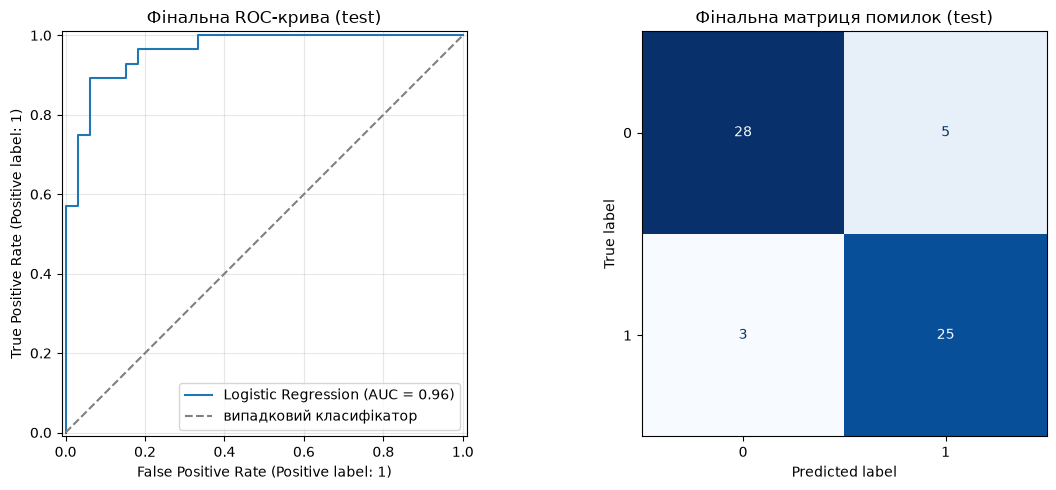

TN = 28, FP = 5, FN = 3, TP = 25


In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(
    y_test, test_probabilities, pos_label=POSITIVE_CLASS, ax=axes[0], name=final_name
)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="випадковий класифікатор")
axes[0].set_title("Фінальна ROC-крива (test)")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, labels=[0, 1], display_labels=["0", "1"],
    cmap="Blues", colorbar=False, ax=axes[1]
)
axes[1].set_title("Фінальна матриця помилок (test)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr07_test_roc_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, test_predictions, labels=[0, 1]).ravel()
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")

**Результати на test.** Зафіксована модель на 61 тестовому об'єкті має **Accuracy = 0,869**,
**Precision = 0,833**, **Recall = 0,893**, **F1 = 0,862** і **ROC AUC = 0,962**. Із 28 пацієнтів з ознаками
захворювання виявлено 25 (FN = 3), із 33 пацієнтів без ознак 5 хибно віднесено до класу 1 (FP = 5).

**Узгодженість із CV.** Test F1 (0,862) і accuracy (0,869) лежать у межах звичайного розкиду відносно CV
(0,836 і 0,855), тож модель узагальнює без ознак перенавчання. Recall і ROC AUC на test помітно вищі,
ніж за CV (+0,09 і +0,06), а precision — нижча (−0,045). Це не привід вважати модель кращою, ніж
показала CV: test містить лише 61 об'єкт, тому одна помилка змінює recall на ~3,6 п. п., і така різниця
очікувана для малої вибірки. Модель після перегляду цих результатів не переналаштовувалася.

### 25. Аналіз помилкових прогнозів фінальної моделі

Аналіз пояснює результат і **не використовується для зміни моделі**.

In [51]:
errors = X_test.copy()
errors["справжній клас"] = y_test
errors["прогноз"] = test_predictions
errors["P(клас 1)"] = test_probabilities
errors = errors[errors["справжній клас"] != errors["прогноз"]]
errors["тип помилки"] = np.where(errors["справжній клас"] == 1, "FN", "FP")
errors["відстань до порогу 0,5"] = (errors["P(клас 1)"] - 0.5).abs()

main_features = ["age", "sex", "cp", "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
errors_view = errors[["тип помилки", "справжній клас", "прогноз", "P(клас 1)",
                      "відстань до порогу 0,5"] + main_features].sort_values("P(клас 1)")
errors_view.index.name = "індекс у heart_disease.csv"
display(errors_view.round(3))

print(f"Помилок: {len(errors_view)} з {len(y_test)}; "
      f"близько до межі (|P − 0,5| < 0,2): {(errors_view['відстань до порогу 0,5'] < 0.2).sum()}; "
      f"впевнені помилки (|P − 0,5| ≥ 0,3): {(errors_view['відстань до порогу 0,5'] >= 0.3).sum()}")

,тип помилки,справжній клас,прогноз,P(клас 1),"відстань до порогу 0,5",age,sex,cp,thalach,exang,oldpeak,slope,ca,thal
індекс у heart_disease.csv,,,,,,,,,,,,,,
66,FN,1,0,0.249,0.251,60,1,3,155,0,3.0,2,0.0,3.0
292,FN,1,0,0.411,0.089,44,1,4,144,1,2.8,3,0.0,6.0
172,FN,1,0,0.462,0.038,59,0,4,143,1,0.0,2,0.0,3.0
271,FP,0,1,0.516,0.016,66,1,4,138,0,2.3,1,0.0,6.0
287,FP,0,1,0.597,0.097,58,1,2,144,0,0.4,2,NaN,7.0
196,FP,0,1,0.709,0.209,69,1,1,131,0,0.1,2,1.0,3.0
33,FP,0,1,0.781,0.281,59,1,4,161,0,0.5,2,0.0,7.0
92,FP,0,1,0.925,0.425,62,1,3,146,0,1.8,2,3.0,7.0


Помилок: 8 з 61; близько до межі (|P − 0,5| < 0,2): 4; впевнені помилки (|P − 0,5| ≥ 0,3): 1


In [52]:
# Для порівняння: типові значення ознак правильно класифікованих пацієнтів test за класами
correct = X_test[y_test == test_predictions].assign(target=y_test)
display(correct.groupby("target")[["age", "thalach", "oldpeak", "ca"]].mean().round(2))
display(correct.groupby("target")[["cp", "exang", "thal"]].agg(lambda s: s.mode().iloc[0]))

,age,thalach,oldpeak,ca
target,,,,
0,49.68,160.39,0.47,0.31
1,57.04,135.48,1.96,1.68


,cp,exang,thal
target,,,
0,3,0,3.0
1,4,1,7.0


**Аналіз помилок.** Модель помилилася у **8 з 61** тестових об'єктів: 3 FN і 5 FP.

- **Близькість до межі.** Половина помилок (об'єкти 292, 172, 271, 287) має P(клас 1) у межах 0,41–0,60,
  тобто лежить біля порогу 0,5 — модель сумнівалася.
- **Повторювані характеристики.** Усі три пропущені хворі мають `ca = 0` (ознака з найбільшим від'ємним
  коефіцієнтом), а двоє з них — ще й `thal = 3` (норма): за найсильнішими ознаками вони схожі на здорових.
  Хибні тривоги (FP), навпаки, здебільшого мають ознаки, типові для класу 1: безсимптомний біль `cp = 4`
  (об'єкти 271, 33) або оборотний дефект `thal = 7` (287, 33, 92) та вік 58–69 років. 7 із 8 помилок —
  чоловіки.
- **Надмірна впевненість.** Одна помилка впевнена: об'єкт 92 (62 роки, `ca = 3`, `thal = 7`) отримав
  P = 0,925, хоча ознак захворювання не має; за найважливішими ознаками він виглядає як типовий хворий.
  Об'єкт 66 (FN, P = 0,249) має нетиповий для хворих профіль: `cp = 3`, `ca = 0`, `thal = 3`, високий пульс 155.
- В об'єкті 287 пропущене `ca` заповнено модою 0, що могло зменшити впевненість прогнозу.

Отже, помилки зумовлені переважно перекриттям класів за найінформативнішими ознаками; модель
у межах цього експерименту не змінюється.